# 01 - Data Understanding

Goal of the project: predict district-level crop yield early enough (about 6 weeks before harvest) so the procurement team can plan storage and contracts.

This notebook only looks at the raw file. Nothing is changed here.

One row in the file is one taluka, one crop, one season and one week of that season. The final yield of the season is repeated on every weekly row of that season. That matters later for the train/test split.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw = pd.read_csv('../dataset/raw_dataset.csv')
print(raw.shape)
raw.head()

(348456, 21)
           taluka    district mandi_id   crop  season_year  season_week  abs_week  calendar_week  rain_mm  tmax_c  mandi_price  mandi_arrivals_qtl      soil_N     soil_P      soil_K   soil_pH   soil_OC  irrigated_share       area_ha  yield_reported  season_mandi_arrivals_qpha
0      Wardha-T12      Wardha   WAR-M1    tur         2021           22       722             47     15.3    24.5       137.71               119.4  215.543406  19.335479  262.463588  7.157791  0.564041         0.357466   7641.169318        9.871392                    8.577921
1  Chandrapur-T04  Chandrapur   CHA-M2  wheat         2025           39       966             31      0.0    32.9      6300.60               192.7  270.925040  23.030668  212.420125  7.225086  0.529440         0.423367   4166.653124       36.914369                   33.912620
2  Chandrapur-T05  Chandrapur   CHA-M3   gram         2017           18       526              7     25.1    30.1       100.62             36588.4  221.8192

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 348456 entries, 0 to 348455
Data columns (total 21 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   taluka                      348456 non-null  str    
 1   district                    348456 non-null  str    
 2   mandi_id                    348456 non-null  str    
 3   crop                        348456 non-null  str    
 4   season_year                 348456 non-null  int64  
 5   season_week                 348456 non-null  int64  
 6   abs_week                    348456 non-null  int64  
 7   calendar_week               348456 non-null  int64  
 8   rain_mm                     328114 non-null  float64
 9   tmax_c                      344992 non-null  float64
 10  mandi_price                 348456 non-null  float64
 11  mandi_arrivals_qtl          348456 non-null  float64
 12  soil_N                      314110 non-null  float64
 13  soil_P                   

In [3]:
# columns with missing values
miss = raw.isna().mean().round(3)
miss[miss > 0]

rain_mm    0.058
tmax_c     0.010
soil_N     0.099
soil_P     0.099
soil_K     0.099
soil_pH    0.097
soil_OC    0.097


In [4]:
print('duplicate rows:', raw.duplicated().sum())
print('districts:', raw.district.nunique(), '| talukas:', raw.taluka.nunique(), '| mandis:', raw.mandi_id.nunique())
print('crops:', list(raw.crop.unique()))
print('years:', raw.season_year.min(), 'to', raw.season_year.max())
raw.describe().T[['mean', 'min', 'max']].round(1)

duplicate rows: 696
districts: 6 | talukas: 84 | mandis: 18
crops: ['tur', 'wheat', 'gram', 'cotton', 'soybean']
years: 2008 to 2025
                              mean     min      max
season_year                 2016.5  2008.0   2025.0
season_week                   23.5     1.0     46.0
abs_week                     495.5    21.0    973.0
calendar_week                 26.2     1.0     52.0
rain_mm                       16.4     0.0    871.0
tmax_c                        32.5    18.6     47.2
mandi_price                 7608.7    20.8  18821.6
mandi_arrivals_qtl          1668.6     0.0  90767.7
soil_N                       248.7   127.0    352.7
soil_P                        18.4     5.8     35.2
soil_K                       218.9   125.3    325.0
soil_pH                        7.4     6.2      8.5
soil_OC                        0.5     0.2      0.9
irrigated_share                0.3     0.1      0.5
area_ha                     6286.8   685.7  42271.8
yield_reported                39.1 

## Three things look wrong already

1. `mandi_price`: the minimum for each crop is tiny compared to the median. Some mandis enter price per kg, others per quintal.
2. `yield_reported`: the max is many times the median. Some seasons look like they were entered in kg/ha or t/ha instead of q/ha.
3. `rain_mm` is missing in about 6% of rows. Let me check if the gaps are random.

In [5]:
print(raw.groupby('crop').mandi_price.agg(['min', 'median', 'max']).round(0))
print()
print(raw.groupby('crop').yield_reported.agg(['min', 'median', 'max']).round(1))

          min   median      max
crop                           
cotton   66.0  10974.0  17854.0
gram     49.0   8152.0  17065.0
soybean  42.0   6590.0  11229.0
tur      55.0   9924.0  18822.0
wheat    21.0   3845.0   7230.0

         min  median     max
crop                        
cotton   0.3     6.4   886.8
gram     0.7    12.0  1549.2
soybean  0.9    11.5  1421.3
tur      0.4     7.8  1036.6
wheat    1.6    28.8  4129.2


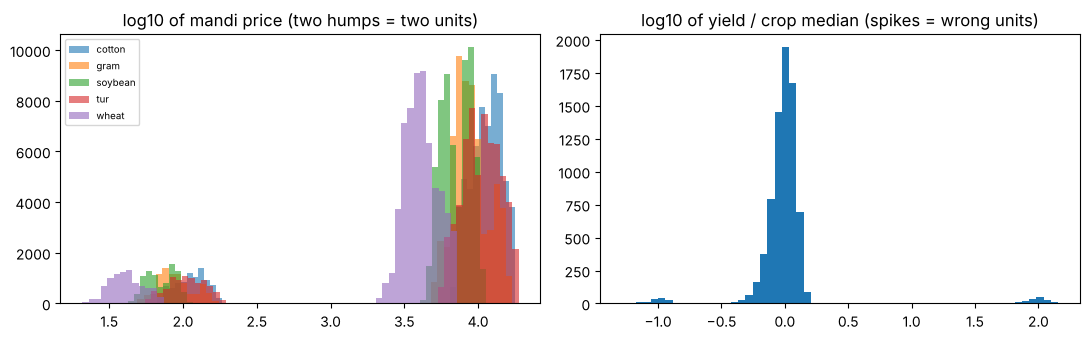

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

for crop, d in raw.groupby('crop'):
    ax[0].hist(np.log10(d.mandi_price), bins=60, alpha=0.6, label=crop)
ax[0].set_title('log10 of mandi price (two humps = two units)')
ax[0].legend(fontsize=7)

one = raw.drop_duplicates(['taluka', 'crop', 'season_year'])
ratio = one.yield_reported / one.groupby('crop').yield_reported.transform('median')
ax[1].hist(np.log10(ratio), bins=60)
ax[1].set_title('log10 of yield / crop median (spikes = wrong units)')
plt.tight_layout()
plt.savefig('../reports/figures/01_unit_problems.png', dpi=120)

rain_band
(0, 5]       0.094
(5, 15]      0.108
(15, 30]     0.133
(30, 60]     0.159
(60, 500]    0.181
Name: rain_mm, dtype: float64


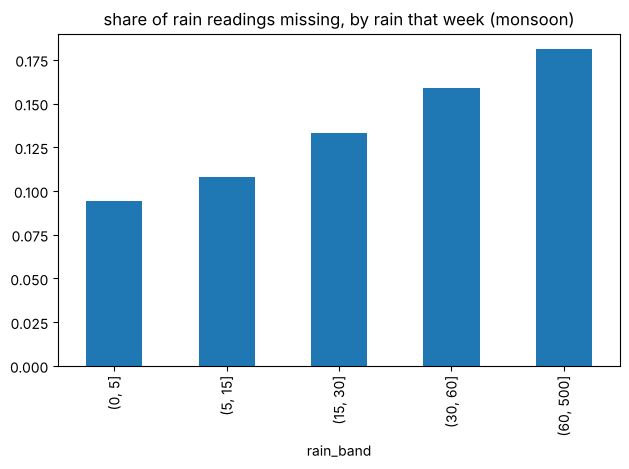

In [7]:
# is rainfall missing at random? compare with how much rain the district got that week
w = raw.drop_duplicates(['taluka', 'abs_week'])[['district', 'abs_week', 'calendar_week', 'rain_mm']].copy()
w['district_rain'] = w.groupby(['district', 'abs_week']).rain_mm.transform('mean')
w = w[w.calendar_week.between(23, 40)].dropna(subset=['district_rain'])
w['rain_band'] = pd.cut(w.district_rain, [0, 5, 15, 30, 60, 500])
miss_rate = w.groupby('rain_band').rain_mm.apply(lambda s: s.isna().mean())
print(miss_rate.round(3))
miss_rate.plot.bar(title='share of rain readings missing, by rain that week (monsoon)')
plt.tight_layout()
plt.savefig('../reports/figures/01_rain_missing.png', dpi=120)

## Notes

- Prices mix INR/kg and INR/quintal. Fix: if a price is far below the crop's usual level, multiply by 100.
- Yield has wrong units in a few percent of seasons. Fix: compare each season with the crop median and rescale.
- Rain gaps are not random. They are more common in heavy-rain weeks (gauges fail in storms). If I just drop or mean-fill them, the model will think the monsoon was drier than it was. I will fill from neighbouring talukas in the same week and keep a flag.
- Duplicate rows exist and will be dropped.
- Soil test values are missing for some taluka-years.

Next: 02_Data_Cleaning.